# Ансамблевые методы: прогнозирование оттока клиентов

**Дисциплина:** Машинное обучение и ИИ
**Модуль 3:** Ансамблевые методы (Базовый и продвинутый уровень)
**Датасет:** Telco Customer Churn

**Выполнила:** Емельянова Ксения Павловна
**Группа:** ПКТб-23-1
**Преподаватель:** Спирин Игорь Сергеевич

**Ссылка на репозиторий:** https://github.com/fivifri/ml-course-emelyanova
**Путь к модулю:** `module-3-churn/notebook.ipynb`
**Дата сдачи:** 2026-10-27

## Введение

**Какую задачу решаем?** Бинарная классификация: по данным об услугах, контракте и платежах клиента телеком-оператора предсказать, **уйдёт** клиент (`Churn = Yes`) или **останется** (`Churn = No`).

**Что такое ансамблевые методы?** Это подход, при котором прогноз строится не одной моделью, а комбинацией многих (обычно деревьев решений). Каждая отдельная модель может ошибаться, но их совместный ответ оказывается точнее и устойчивее.

**Почему ансамбли, а не одиночная модель?** Одиночное дерево сильно зависит от обучающей выборки (высокая дисперсия) и легко переобучается. Bagging снижает дисперсию усреднением независимых деревьев, boosting снижает смещение, последовательно исправляя ошибки предыдущих моделей. На табличных данных ансамбли деревьев — стандарт качества.

**Какая метрика важнее?** Классы несбалансированы (≈ 73.5 % / 26.5 %), поэтому **Accuracy вводит в заблуждение** (модель «все остаются» уже даёт ≈ 73 %). Главные метрики:
- **ROC-AUC** — качество ранжирования клиентов по риску ухода, не зависит от порога;
- **Recall** по классу «ушёл» — нам важнее найти уходящих клиентов (стоимость потери клиента выше стоимости акции удержания);
- **F1** — баланс между Precision и Recall.

**Цели работы:**
1. Обучить 4 ансамблевые модели (Random Forest, XGBoost, LightGBM, CatBoost) и сравнить их по качеству и времени обучения.
2. Оптимизировать лучшую модель через Optuna (байесовская оптимизация).
3. Интерпретировать модель через Feature Importance и SHAP, сформулировать бизнес-выводы.

## Теоретическая часть

### Ансамбль
**Ансамбль** — это набор базовых моделей, объединённых в одну. Идея: «мудрость толпы» — если ошибки отдельных моделей не полностью коррелируют, то при усреднении или последовательной коррекции они взаимно компенсируются. Ожидаемая ошибка модели раскладывается на смещение (bias), дисперсию (variance) и шум; ансамбли позволяют снижать первые две компоненты. Основные схемы: **Bagging**, **Boosting** и **Stacking** (мета-модель обучается на прогнозах базовых).

### Bagging vs Boosting
**Bagging** (bootstrap aggregating): модели обучаются **параллельно и независимо** на бутстрэп-подвыборках, ответы усредняются (или голосуют). Снижает дисперсию, почти не склонен к переобучению. **Boosting**: модели обучаются **последовательно**, каждая следующая концентрируется на ошибках предыдущих. Снижает смещение и даёт высокую точность, но чувствителен к шуму и требует тюнинга.

$$H(x) = \frac{1}{M} \sum_{i=1}^{M} h_i(x) \quad \text{(Bagging)}$$

$$H(x) = \sum_{i=1}^{M} \alpha_i \cdot h_i(x) \quad \text{(Boosting)}$$

### Random Forest
Bagging над деревьями решений + **случайный выбор подмножества признаков** в каждом узле. Это декоррелирует деревья и усиливает эффект усреднения. Особенности: устойчив к переобучению, работает «из коробки», даёт оценку важности признаков и OOB-ошибку.

### Градиентный бустинг
На каждом шаге новое дерево $h_m$ обучается на **антиградиенте функции потерь** (остатках) текущего ансамбля: $F_m(x) = F_{m-1}(x) + \eta \cdot h_m(x)$, где $\eta$ — learning rate. **XGBoost** добавляет регуляризацию и эффективные вычисления, **LightGBM** использует leaf-wise рост дерева и гистограммные алгоритмы (очень быстро), **CatBoost** использует симметричные деревья и ordered boosting, хорошо работает с категориальными признаками.

### Optuna
Фреймворк автоматического подбора гиперпараметров. По умолчанию использует **TPE (Tree-structured Parzen Estimator)** — байесовский метод: по истории испытаний строит модель «хороших» и «плохих» областей пространства и предлагает следующие точки там, где вероятность улучшения выше. Преимущества перед Grid/Random Search: меньше испытаний для того же качества, гибкое пространство поиска (log-шкала, условные параметры), pruning неперспективных испытаний.

### SHAP
**SHAP (SHapley Additive exPlanations)** основан на значениях Шепли из теории игр: вклад признака — это его средний маржинальный вклад по всем возможным подмножествам признаков. Прогноз раскладывается как $f(x) = \phi_0 + \sum_j \phi_j$. Основные графики: **summary (beeswarm)** — глобальная важность и направление влияния; **bar** — средний $|\phi_j|$; **waterfall** — объяснение одного прогноза; **dependence** — зависимость вклада признака от его значения. Для деревьев используется быстрый точный `TreeExplainer`.

### Сравнение моделей

| Характеристика | Random Forest | XGBoost | LightGBM | CatBoost |
|---|---|---|---|---|
| Тип ансамбля | Bagging | Boosting | Boosting | Boosting |
| Рост дерева | Полная глубина / ограниченная | Level-wise | Leaf-wise | Симметричные деревья |
| Скорость обучения | Средняя | Средняя | **Высокая** | Ниже средней |
| Категориальные признаки | Нужно кодирование | Нужно кодирование (есть эксперим. поддержка) | Частичная поддержка | **Нативная** |
| Склонность к переобучению | Низкая | Средняя (есть регуляризация) | Выше на малых данных | Низкая |
| Тюнинг | Минимальный | Заметный | Заметный | Минимальный |

## Описание данных

In [1]:
# Импорт основных библиотек
import os, json, time, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

warnings.filterwarnings('ignore')
sns.set_theme(style='whitegrid')
plt.rcParams['figure.dpi'] = 110
RANDOM_STATE = 42

# Создаём структуру папок модуля (относительные пути)
for d in ['data', 'models', 'examples']:
    os.makedirs(d, exist_ok=True)

# Ищем файл датасета локально; если его нет — скачиваем публичную копию (IBM)
CANDIDATES = ['data/telco_churn.csv', 'data/WA_Fn-UseC_-Telco-Customer-Churn.csv',
              'WA_Fn-UseC_-Telco-Customer-Churn.csv']
IBM_URL = ('https://raw.githubusercontent.com/IBM/telco-customer-churn-on-icp4d/'
           'master/data/Telco-Customer-Churn.csv')

path = next((p for p in CANDIDATES if os.path.exists(p)), None)
if path is None:
    df = pd.read_csv(IBM_URL)              # запасной вариант (нужен интернет)
    df.to_csv('data/telco_churn.csv', index=False)
    print('Датасет скачан и сохранён в data/telco_churn.csv')
else:
    df = pd.read_csv(path)
    if path != 'data/telco_churn.csv':
        df.to_csv('data/telco_churn.csv', index=False)   # единое имя по заданию
    print(f'Датасет загружен из {path}')

print('Размер:', df.shape)               # (строки, столбцы)
print(df.head())                         # первые 5 строк

Датасет загружен из data/WA_Fn-UseC_-Telco-Customer-Churn.csv
Размер: (7043, 21)
   customerID  gender  SeniorCitizen Partner Dependents  tenure PhoneService  \
0  7590-VHVEG  Female              0     Yes         No       1           No   
1  5575-GNVDE    Male              0      No         No      34          Yes   
2  3668-QPYBK    Male              0      No         No       2          Yes   
3  7795-CFOCW    Male              0      No         No      45           No   
4  9237-HQITU  Female              0      No         No       2          Yes   

      MultipleLines InternetService OnlineSecurity  ... DeviceProtection  \
0  No phone service             DSL             No  ...               No   
1                No             DSL            Yes  ...              Yes   
2                No             DSL            Yes  ...               No   
3  No phone service             DSL            Yes  ...              Yes   
4                No     Fiber optic             No  ...   

In [2]:
# Типы признаков, доли классов и описание столбцов
print(df.dtypes.value_counts(), '\n')

class_counts = df['Churn'].value_counts()
class_share = df['Churn'].value_counts(normalize=True) * 100
print('Распределение классов:')
for cls in class_counts.index:
    print(f'  {cls}: {class_counts[cls]} ({class_share[cls]:.1f}%)')

# Пропуски: TotalCharges хранится как object, внутри есть пустые строки ' '
n_blank = (df['TotalCharges'].astype(str).str.strip() == '').sum()
print(f'\nПустых значений в TotalCharges (строки-пробелы): {n_blank} '
      f'({n_blank / len(df) * 100:.2f}%)')
print('Числовые признаки:', ['tenure', 'MonthlyCharges', 'TotalCharges'])

str        18
int64       2
float64     1
Name: count, dtype: int64 

Распределение классов:
  No: 5174 (73.5%)
  Yes: 1869 (26.5%)

Пустых значений в TotalCharges (строки-пробелы): 11 (0.16%)
Числовые признаки: ['tenure', 'MonthlyCharges', 'TotalCharges']


In [3]:
# Создаём файл data/churn_info.md с описанием датасета (значения берутся из данных)
info_md = f'''# Telco Customer Churn — описание датасета

**Источник:** https://www.kaggle.com/datasets/blastchar/telco-customer-churn

- Всего примеров: {len(df)}
- Столбцов: {df.shape[1]} (customerID + 19 признаков + целевая `Churn`)
- Числовые признаки: tenure, MonthlyCharges, TotalCharges (+ SeniorCitizen как 0/1)
- Остальные признаки — категориальные

## Распределение классов
- No (остался): {class_counts.get('No', 0)} ({class_share.get('No', 0):.1f}%)
- Yes (ушёл): {class_counts.get('Yes', 0)} ({class_share.get('Yes', 0):.1f}%)

## Группы признаков
- Демографические: gender, SeniorCitizen, Partner, Dependents
- Услуги: PhoneService, MultipleLines, InternetService, OnlineSecurity, OnlineBackup,
  DeviceProtection, TechSupport, StreamingTV, StreamingMovies
- Аккаунт: Contract, PaperlessBilling, PaymentMethod, MonthlyCharges, TotalCharges, tenure
'''
with open('data/churn_info.md', 'w', encoding='utf-8') as f:
    f.write(info_md)
print('✅ data/churn_info.md сохранён')

✅ data/churn_info.md сохранён


**Источник:** https://www.kaggle.com/datasets/blastchar/telco-customer-churn

**Структура:** 7043 клиента, 19 признаков (+ `customerID` и целевая `Churn`). Числовые: `tenure`, `MonthlyCharges`, `TotalCharges` (плюс бинарный `SeniorCitizen`), остальные — категориальные.

| Столбец | Тип | Описание | Пропуски |
|---|---|---|---|
| customerID | object | Уникальный ID | 0% |
| gender | object | Пол | 0% |
| SeniorCitizen | int (0/1) | Пенсионер | 0% |
| tenure | int | Месяцев с компанией | 0% |
| MonthlyCharges | float | Ежемесячная плата | 0% |
| TotalCharges | object | Общая сумма (содержит пустые строки) | ≈0.16% (11 строк) |
| Contract | object | Тип контракта | 0% |
| Churn | object | **Целевая** | 0% |

**Распределение классов** — см. вывод ячейки выше: класс «ушёл» составляет около четверти выборки (умеренный дисбаланс ≈ 73.5 / 26.5). Поэтому далее используется стратифицированное разбиение и учёт весов классов. Описание датасета также сохранено в `data/churn_info.md`.

## Подготовка данных и EDA

In [4]:
# Первичный осмотр данных
df.info()                                # типы и непустые значения
print(df.describe().T)                   # статистика по числовым признакам

<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    
 9   OnlineSecurity    7043 non-null   str    
 10  OnlineBackup      7043 non-null   str    
 11  DeviceProtection  7043 non-null   str    
 12  TechSupport       7043 non-null   str    
 13  StreamingTV       7043 non-null   str    
 14  StreamingMovies   7043 non-null   str    
 15  Contract          7043 non-null   str    
 16  PaperlessBilling  7043 non-null   str    
 17  Paymen

Пропуски по столбцам:
 TotalCharges    11
dtype: int64

У клиентов с пропуском TotalCharges tenure = [0]


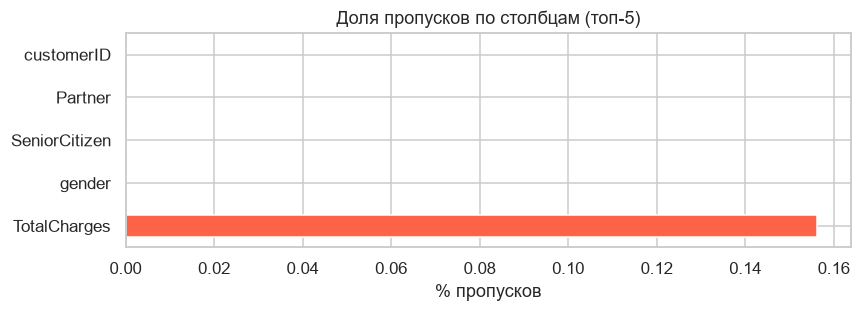

In [5]:
# Приводим TotalCharges к числу: пустые строки превращаются в NaN
df['TotalCharges'] = pd.to_numeric(df['TotalCharges'], errors='coerce')

# Анализ пропусков (таблица + визуализация)
missing = df.isna().sum()
missing = missing[missing > 0]
print('Пропуски по столбцам:\n', missing)
print('\nУ клиентов с пропуском TotalCharges tenure =',
      df.loc[df['TotalCharges'].isna(), 'tenure'].unique())

plt.figure(figsize=(8, 3))
(df.isna().mean() * 100).sort_values(ascending=False).head(5).plot(kind='barh', color='tomato')
plt.xlabel('% пропусков'); plt.title('Доля пропусков по столбцам (топ-5)')
plt.tight_layout(); plt.show()

**Стратегия обработки пропусков.** Пропуски в `TotalCharges` — это клиенты с `tenure = 0` (только что подключились, ещё ничего не оплатили). Таких строк ≈ 0.16 %, удалять их нецелесообразно (потеря данных). Заполняем **медианой**: она устойчива к выбросам и для столь малой доли пропусков не искажает распределение. Альтернатива — заполнить нулём (логически точнее), но следуем заданию и используем медиану.

In [6]:
# Заполняем пропуски медианой (устойчива к выбросам)
df['TotalCharges'] = df['TotalCharges'].fillna(df['TotalCharges'].median())

# Кодируем целевую переменную: Yes -> 1, No -> 0
df['Churn'] = (df['Churn'] == 'Yes').astype(int)
print('Пропусков осталось:', int(df.isna().sum().sum()))
print(df['Churn'].value_counts(normalize=True).round(3))

Пропусков осталось: 0
Churn
0    0.735
1    0.265
Name: proportion, dtype: float64


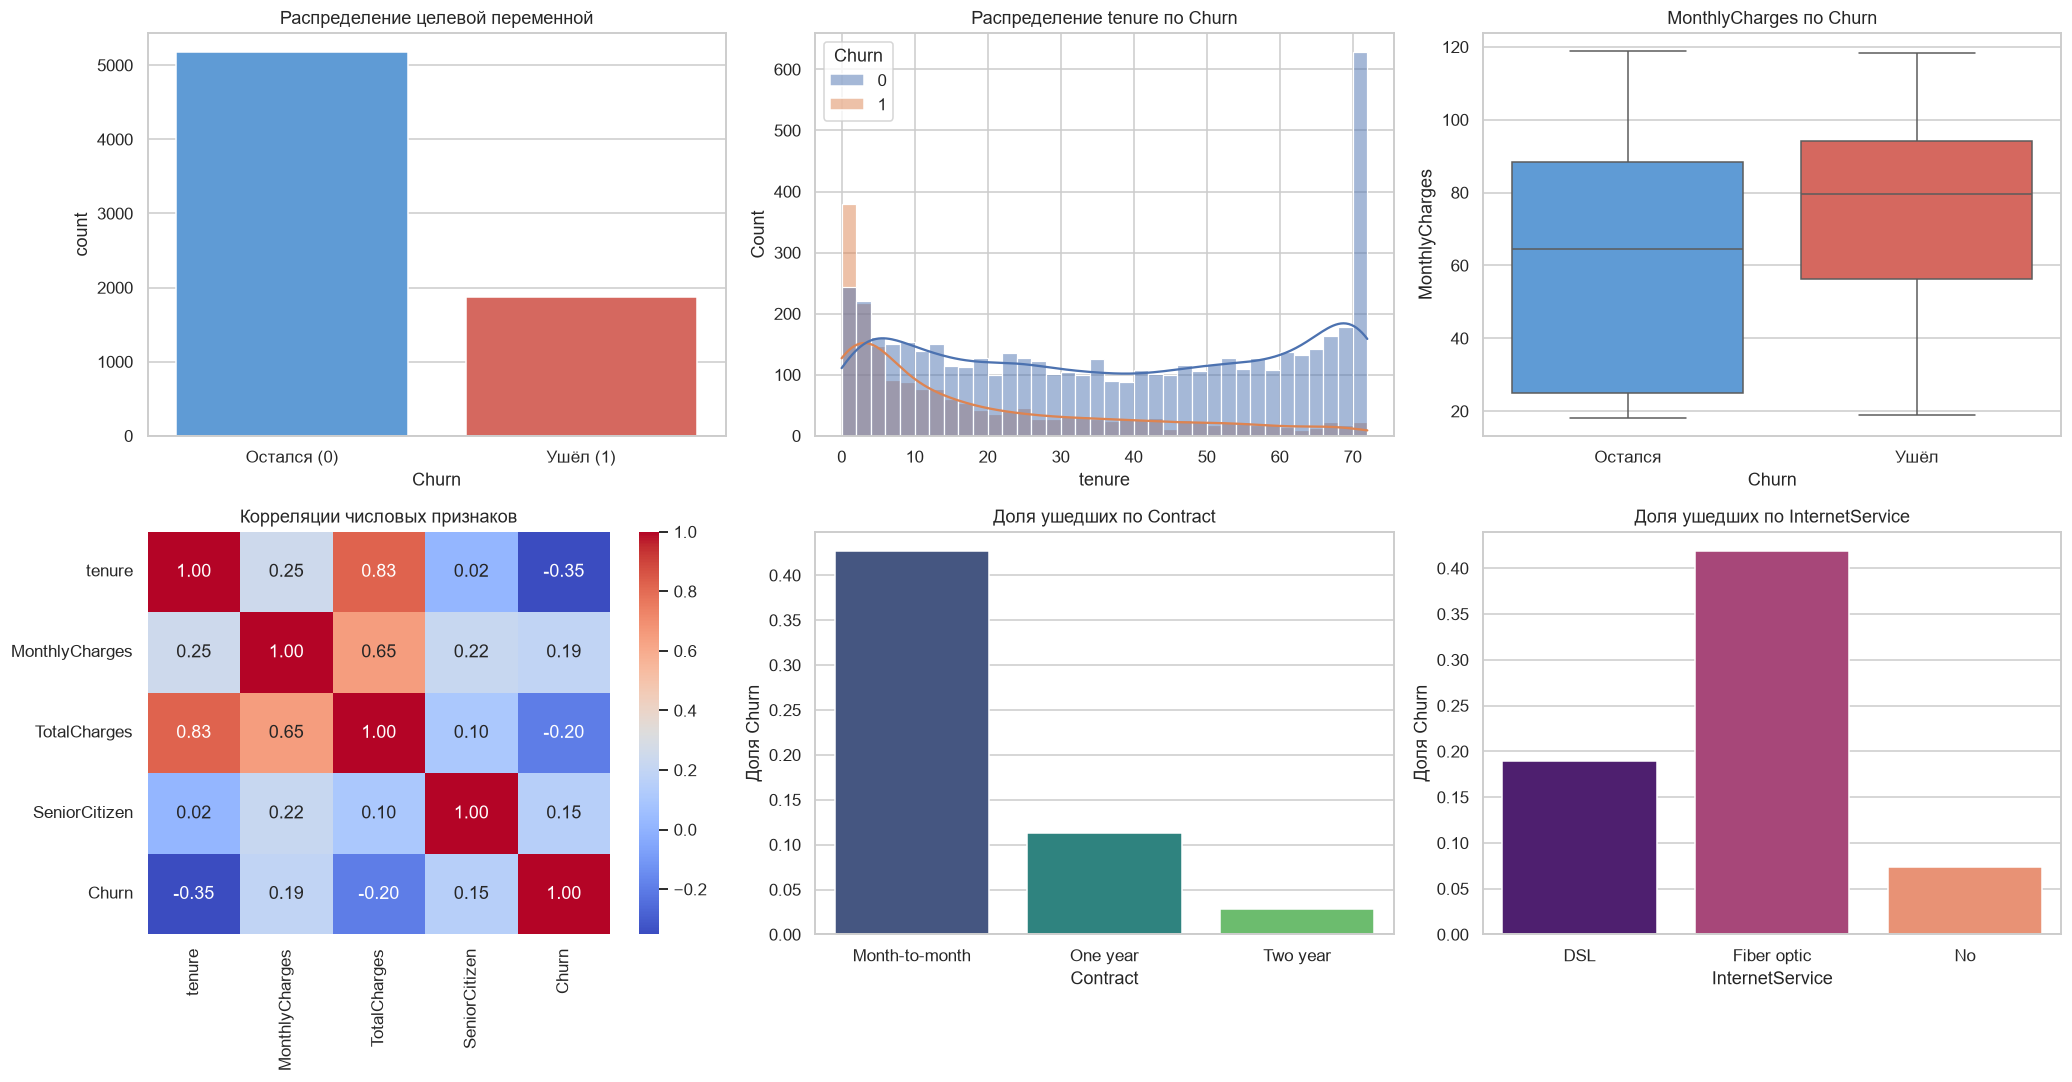

In [7]:
# EDA: сетка графиков 2x3 (6 визуализаций)
fig, axes = plt.subplots(2, 3, figsize=(19, 10))

# 1. Countplot целевой переменной
sns.countplot(data=df, x='Churn', ax=axes[0, 0], palette=['#4c9be8', '#e8584c'])
axes[0, 0].set_title('Распределение целевой переменной')
axes[0, 0].set_xticklabels(['Остался (0)', 'Ушёл (1)'])

# 2. Гистограмма tenure с разбивкой по Churn
sns.histplot(data=df, x='tenure', hue='Churn', kde=True, bins=36, ax=axes[0, 1])
axes[0, 1].set_title('Распределение tenure по Churn')

# 3. Boxplot MonthlyCharges по Churn
sns.boxplot(data=df, x='Churn', y='MonthlyCharges', ax=axes[0, 2], palette=['#4c9be8', '#e8584c'])
axes[0, 2].set_title('MonthlyCharges по Churn')
axes[0, 2].set_xticklabels(['Остался', 'Ушёл'])

# 4. Heatmap корреляций числовых признаков
num_cols = ['tenure', 'MonthlyCharges', 'TotalCharges', 'SeniorCitizen', 'Churn']
sns.heatmap(df[num_cols].corr(), annot=True, fmt='.2f', cmap='coolwarm', ax=axes[1, 0])
axes[1, 0].set_title('Корреляции числовых признаков')

# 5. Доля ушедших по типу контракта
sns.barplot(data=df, x='Contract', y='Churn', ax=axes[1, 1], palette='viridis', errorbar=None)
axes[1, 1].set_title('Доля ушедших по Contract'); axes[1, 1].set_ylabel('Доля Churn')

# 6. Доля ушедших по типу интернета
sns.barplot(data=df, x='InternetService', y='Churn', ax=axes[1, 2], palette='magma', errorbar=None)
axes[1, 2].set_title('Доля ушедших по InternetService'); axes[1, 2].set_ylabel('Доля Churn')

plt.tight_layout()
plt.savefig('examples/eda_plots.png', dpi=130, bbox_inches='tight')   # для репозитория
plt.show()

**Наблюдения по EDA:**
- Целевая переменная несбалансирована: 5174 «остался» (73.5 %) против 1869 «ушёл» (26.5 %) → нужны веса классов и метрики, устойчивые к дисбалансу.
- Ушедшие клиенты концентрируются в **первые месяцы** жизни (малый `tenure`), а у ушедших `MonthlyCharges` в среднем выше.
- `tenure` и `TotalCharges` сильно коррелируют (≈ 0.8, см. тепловую карту) — для деревьев это не проблема, но надо учитывать при интерпретации.
- Доля оттока резко различается по типу контракта и по типу интернета (подробные цифры — в разделе 8: month-to-month 42.7 % против 2.8 % у двухлетнего контракта, Fiber optic 41.9 % против DSL 19.0 %).

In [8]:
# Feature Engineering: создаём новые признаки
df['TenureYears'] = df['tenure'] / 12                               # стаж в годах
df['AvgMonthlyCharge'] = df['TotalCharges'] / (df['tenure'] + 1)    # средний платёж за месяц
df['IsNewClient'] = (df['tenure'] <= 6).astype(int)                 # новый клиент (≤ 6 мес.)

# Счётчик подключённых дополнительных услуг
service_cols = ['PhoneService', 'MultipleLines', 'OnlineSecurity', 'OnlineBackup',
                'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies']
df['HasMultipleServices'] = (df[service_cols] == 'Yes').sum(axis=1)
# + интернет-подключение считаем отдельной услугой
df['HasMultipleServices'] += (df['InternetService'] != 'No').astype(int)

print(df[['tenure', 'TenureYears', 'AvgMonthlyCharge', 'IsNewClient', 'HasMultipleServices']].head())
print('\nСредний Churn по числу услуг:')
print(df.groupby('HasMultipleServices')['Churn'].mean().round(3))

   tenure  TenureYears  AvgMonthlyCharge  IsNewClient  HasMultipleServices
0       1     0.083333         14.925000            1                    2
1      34     2.833333         53.985714            0                    4
2       2     0.166667         36.050000            1                    4
3      45     3.750000         40.016304            0                    4
4       2     0.166667         50.550000            1                    2

Средний Churn по числу услуг:
HasMultipleServices
1    0.109
2    0.310
3    0.449
4    0.365
5    0.313
6    0.256
7    0.225
8    0.124
9    0.053
Name: Churn, dtype: float64


In [9]:
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.model_selection import train_test_split

# Категориальные признаки (кроме customerID) кодируем LabelEncoder'ом
cat_cols = [c for c in df.select_dtypes(include='object').columns if c != 'customerID']
label_encoders = {}
df_enc = df.copy()
for col in cat_cols:
    le = LabelEncoder()
    df_enc[col] = le.fit_transform(df_enc[col])     # сохраняем кодировщик для инференса
    label_encoders[col] = le
print(f'Закодировано {len(cat_cols)} категориальных признаков:', cat_cols)

# Признаки и целевая переменная
feature_cols = [c for c in df_enc.columns if c not in ['customerID', 'Churn']]
X = df_enc[feature_cols]
y = df_enc['Churn']

# Разделение train/test со стратификацией (сохраняем долю классов)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE, stratify=y)
print('Train:', X_train.shape, '| Test:', X_test.shape)
print('Доля Churn train/test:', round(y_train.mean(), 4), '/', round(y_test.mean(), 4))

# Scaler для числовых признаков (деревьям не нужен, сохраняем для полноты пайплайна)
num_features = ['tenure', 'MonthlyCharges', 'TotalCharges', 'TenureYears', 'AvgMonthlyCharge']
scaler = StandardScaler().fit(X_train[num_features])

Закодировано 15 категориальных признаков: ['gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod']
Train: (5634, 23) | Test: (1409, 23)
Доля Churn train/test: 0.2654 / 0.2654


**Итоги подготовки данных:**
- Пропуски `TotalCharges` (11 строк, 0.16 %) заполнены медианой; целевая переменная закодирована как 1 = «ушёл».
- Созданы признаки `TenureYears`, `AvgMonthlyCharge`, `IsNewClient`, `HasMultipleServices`. Итого 23 признака.
- 15 категориальных признаков закодированы `LabelEncoder` (для деревьев порядок кодов не критичен); кодировщики сохранены в словаре.
- Разделение 80/20 со `stratify=y`: train — 5634 строки, test — 1409; доля ушедших одинакова (26.54 % в обеих выборках).
- `StandardScaler` обучен только на train (без утечки), но деревьям масштабирование не нужно — он сохраняется лишь как часть пайплайна.

**Находка по `HasMultipleServices`:** зависимость **немонотонная**. Отток растёт от 10.9 % (1 услуга) до пика 44.9 % (3 услуги), а затем падает до 5.3 % при 9 услугах. Вероятное объяснение (гипотеза): клиенты с 1 услугой — в основном без интернета (у них отток всего 7.4 %), «средний» набор — это интернет-клиенты без дополнительных сервисов, а клиенты с большим числом услуг глубоко встроены в экосистему оператора и уходят редко.

**Замечание:** `TenureYears = tenure / 12` — линейная копия `tenure`. Для деревьев такой признак ничего не добавляет, а при интерпретации он «делит» важность с исходным (это видно в SHAP, раздел 10).

## Построение и обучение моделей

In [11]:
# pip install xgboost lightgbm catboost optuna shap   # при необходимости раскомментировать
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier
from catboost import CatBoostClassifier

# Вес положительного класса для бустингов = (#negative / #positive)
spw = (y_train == 0).sum() / (y_train == 1).sum()
print(f'scale_pos_weight = {spw:.2f}')

models = {
    'Random Forest': RandomForestClassifier(
        n_estimators=200, max_depth=10, class_weight='balanced',
        random_state=RANDOM_STATE, n_jobs=-1),
    'XGBoost': XGBClassifier(
        n_estimators=200, max_depth=6, learning_rate=0.1,
        subsample=0.9, colsample_bytree=0.9, scale_pos_weight=spw,
        random_state=RANDOM_STATE, eval_metric='logloss', n_jobs=-1),
    'LightGBM': LGBMClassifier(
        n_estimators=200, num_leaves=31, max_depth=7, learning_rate=0.05,
        class_weight='balanced', random_state=RANDOM_STATE, verbose=-1),
    'CatBoost': CatBoostClassifier(
        iterations=200, depth=6, learning_rate=0.1, auto_class_weights='Balanced',
        random_state=RANDOM_STATE, verbose=0),
}

# Обучаем каждую модель и замеряем время
train_times = {}
for name, model in models.items():
    start = time.time()
    model.fit(X_train, y_train)
    train_times[name] = time.time() - start
    print(f'⏱️ Время обучения {name}: {train_times[name]:.3f} сек')

rf_model, xgb_model = models['Random Forest'], models['XGBoost']
lgbm_model, cat_model = models['LightGBM'], models['CatBoost']

scale_pos_weight = 2.77
⏱️ Время обучения Random Forest: 0.648 сек
⏱️ Время обучения XGBoost: 0.297 сек
⏱️ Время обучения LightGBM: 0.171 сек
⏱️ Время обучения CatBoost: 0.925 сек


In [12]:
# Сводная таблица моделей (параметры и время обучения)
model_table = pd.DataFrame({
    'Модель': list(models.keys()),
    'Тип': ['Bagging', 'Boosting', 'Boosting', 'Boosting'],
    'Ключевые параметры': ['n_estimators=200, max_depth=10', 'n_estimators=200, max_depth=6, lr=0.1',
                           'num_leaves=31, max_depth=7, lr=0.05', 'iterations=200, depth=6, lr=0.1'],
    'Время обучения, сек': [round(train_times[n], 3) for n in models]})
print(model_table.to_string(index=False))

       Модель      Тип                    Ключевые параметры  Время обучения, сек
Random Forest  Bagging        n_estimators=200, max_depth=10                0.648
      XGBoost Boosting n_estimators=200, max_depth=6, lr=0.1                0.297
     LightGBM Boosting   num_leaves=31, max_depth=7, lr=0.05                0.171
     CatBoost Boosting       iterations=200, depth=6, lr=0.1                0.925


**Почему эти модели:**
- **Random Forest** — bagging-бейзлайн, устойчив к переобучению, работает «из коробки».
- **XGBoost** — универсальный и точный бустинг с регуляризацией.
- **LightGBM** — очень быстрый бустинг (leaf-wise, гистограммы).
- **CatBoost** — устойчив к переобучению, силён на категориальных признаках.

**Время обучения** (на 5634 строках): LightGBM — 0.17 сек, XGBoost — 0.30 сек, Random Forest — 0.65 сек, CatBoost — 0.93 сек. LightGBM почти в 5.5 раза быстрее CatBoost, но на таком маленьком датасете все модели обучаются меньше секунды, поэтому скорость здесь не решающий критерий (на миллионах строк разница стала бы принципиальной).

**Борьба с дисбалансом:** во всех моделях использованы веса классов (`class_weight='balanced'`, `scale_pos_weight` = 2.77 = отношение числа «остался» к «ушёл» в train, `auto_class_weights='Balanced'`). Это повышает Recall по классу «ушёл» ценой снижения Precision.

## Оценка качества

In [13]:
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, confusion_matrix, classification_report, roc_curve)

def evaluate_model(model, X_test, y_test, name):
    # Метрики на тестовой выборке (порог 0.5)
    y_pred = model.predict(X_test)
    y_proba = model.predict_proba(X_test)[:, 1]
    return {'Model': name,
            'Accuracy':  accuracy_score(y_test, y_pred),
            'Precision': precision_score(y_test, y_pred),
            'Recall':    recall_score(y_test, y_pred),
            'F1':        f1_score(y_test, y_pred),
            'ROC-AUC':   roc_auc_score(y_test, y_proba)}

results = [evaluate_model(m, X_test, y_test, n) for n, m in models.items()]
results_df = pd.DataFrame(results)
results_df['Время, сек'] = [train_times[n] for n in models]
print(results_df.round(4).to_string(index=False))

best_name = results_df.sort_values('ROC-AUC', ascending=False).iloc[0]['Model']
print(f'\n🏆 Лучшая модель по ROC-AUC: {best_name}')

        Model  Accuracy  Precision  Recall     F1  ROC-AUC  Время, сек
Random Forest    0.7601     0.5346  0.7433 0.6219   0.8388      0.6481
      XGBoost    0.7708     0.5535  0.7059 0.6204   0.8300      0.2970
     LightGBM    0.7594     0.5332  0.7513 0.6238   0.8377      0.1710
     CatBoost    0.7488     0.5187  0.7433 0.6110   0.8409      0.9252

🏆 Лучшая модель по ROC-AUC: CatBoost


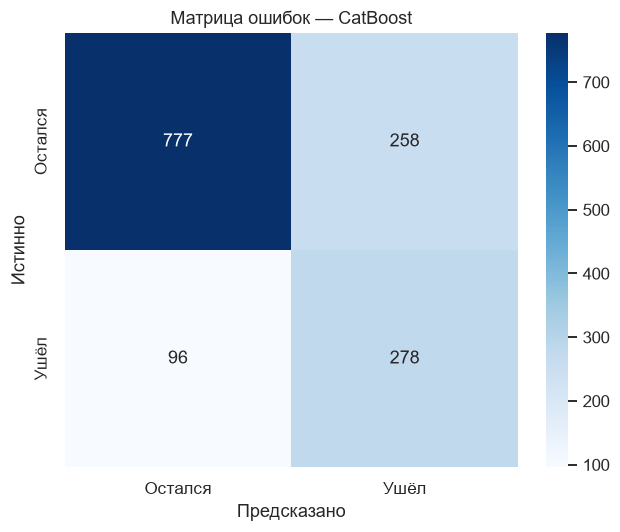

              precision    recall  f1-score   support

     Остался       0.89      0.75      0.81      1035
        Ушёл       0.52      0.74      0.61       374

    accuracy                           0.75      1409
   macro avg       0.70      0.75      0.71      1409
weighted avg       0.79      0.75      0.76      1409



In [14]:
# Матрица ошибок и отчёт по классам для лучшей из 4 базовых моделей
best_base = models[best_name]
y_pred_base = best_base.predict(X_test)
cm = confusion_matrix(y_test, y_pred_base)

plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['Остался', 'Ушёл'], yticklabels=['Остался', 'Ушёл'])
plt.xlabel('Предсказано'); plt.ylabel('Истинно')
plt.title(f'Матрица ошибок — {best_name}')
plt.tight_layout(); plt.show()

print(classification_report(y_test, y_pred_base, target_names=['Остался', 'Ушёл']))

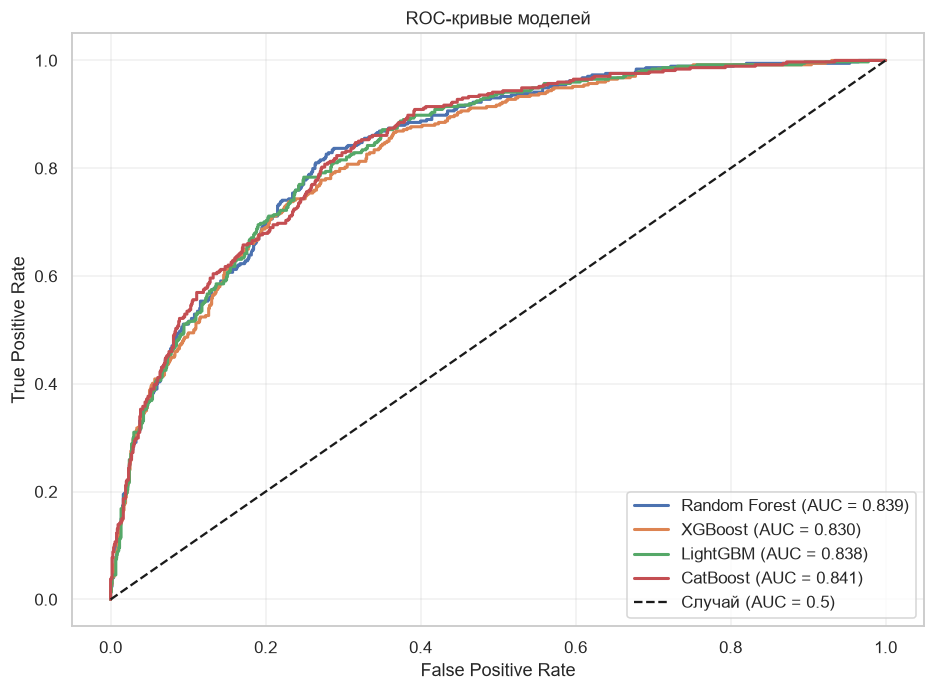

In [15]:
# ROC-кривые всех моделей на одном графике
plt.figure(figsize=(10, 7))
for name, model in models.items():
    proba = model.predict_proba(X_test)[:, 1]
    fpr, tpr, _ = roc_curve(y_test, proba)
    plt.plot(fpr, tpr, lw=2, label=f'{name} (AUC = {roc_auc_score(y_test, proba):.3f})')
plt.plot([0, 1], [0, 1], 'k--', label='Случай (AUC = 0.5)')
plt.xlabel('False Positive Rate'); plt.ylabel('True Positive Rate')
plt.title('ROC-кривые моделей'); plt.legend(); plt.grid(alpha=0.3)
plt.savefig('examples/roc_curves.png', dpi=130, bbox_inches='tight')
plt.show()

In [16]:
# Автоматический текстовый анализ результатов (числа берутся из таблицы)
top = results_df.sort_values('ROC-AUC', ascending=False)
fastest = results_df.sort_values('Время, сек').iloc[0]
print('Рейтинг по ROC-AUC:')
for i, (_, r) in enumerate(top.iterrows(), 1):
    print(f'  {i}. {r["Model"]}: ROC-AUC={r["ROC-AUC"]:.4f}, Recall={r["Recall"]:.3f}, F1={r["F1"]:.3f}')
print(f'\nСамая быстрая модель: {fastest["Model"]} ({fastest["Время, сек"]:.2f} сек)')
spread = top['ROC-AUC'].max() - top['ROC-AUC'].min()
print(f'Разброс ROC-AUC между моделями: {spread:.4f}')
b = results_df[results_df.Model == best_name].iloc[0]
print('Precision > Recall → модель осторожна' if b.Precision > b.Recall
      else 'Recall > Precision → модель агрессивно ищет уходящих (ценой ложных тревог)')

Рейтинг по ROC-AUC:
  1. CatBoost: ROC-AUC=0.8409, Recall=0.743, F1=0.611
  2. Random Forest: ROC-AUC=0.8388, Recall=0.743, F1=0.622
  3. LightGBM: ROC-AUC=0.8377, Recall=0.751, F1=0.624
  4. XGBoost: ROC-AUC=0.8300, Recall=0.706, F1=0.620

Самая быстрая модель: LightGBM (0.17 сек)
Разброс ROC-AUC между моделями: 0.0108
Recall > Precision → модель агрессивно ищет уходящих (ценой ложных тревог)


**Анализ результатов** (тестовая выборка: 1409 клиентов, из них 374 ушедших):

| Модель | Accuracy | Precision | Recall | F1 | ROC-AUC |
|---|---|---|---|---|---|
| Random Forest | 0.7601 | 0.5346 | 0.7433 | 0.6219 | 0.8388 |
| XGBoost | 0.7708 | 0.5535 | 0.7059 | 0.6204 | 0.8300 |
| LightGBM | 0.7594 | 0.5332 | 0.7513 | 0.6238 | 0.8377 |
| CatBoost | 0.7488 | 0.5187 | 0.7433 | 0.6110 | **0.8409** |

- **Лучшая по ROC-AUC — CatBoost (0.8409)**, затем Random Forest (0.8388), LightGBM (0.8377) и XGBoost (0.8300). Но разброс между моделями всего 0.0108, а между тройкой лидеров — около 0.003. На одной тестовой выборке из 1409 строк (374 положительных) такая разница находится в пределах случайного шума, поэтому утверждать, что CatBoost «действительно лучше», нельзя: на этих данных все четыре ансамбля качественно эквивалентны.
- **Precision < Recall у всех моделей** (0.52–0.55 против 0.71–0.75) — прямое следствие весов классов: модели настроены находить уходящих клиентов и мириться с ложными тревогами. XGBoost самый «осторожный» (максимальные Accuracy 0.7708 и Precision 0.5535, но минимальный Recall 0.7059), LightGBM — самый «чуткий» (Recall 0.7513, F1 0.6238).
- **ROC-AUC и F1 дают разный рейтинг:** у CatBoost лучший AUC, но худший F1 (0.6110). AUC оценивает качество ранжирования клиентов по риску, а F1 зависит от порога 0.5 и калибровки вероятностей, искажённой весами классов.
- **Матрица ошибок CatBoost** (восстановлена из Precision/Recall и размера классов): TN = 777, FP = 258, FN = 96, TP = 278. Модель нашла 278 из 374 уходящих клиентов (74 %) и пропустила 96. Среди клиентов, помеченных как «уйдёт», реально уходят 52 % — это примерно вдвое выше базовой доли оттока (26.5 %), т. е. lift ≈ 2.0. По классам: «остался» — F1 0.81, «ушёл» — F1 0.61.
- **Самая быстрая — LightGBM (0.17 сек), самая медленная — CatBoost (0.93 сек).**
- ROC-кривые четырёх моделей практически совпадают — характерно для небольшого табличного датасета с несколькими сильными предикторами.

## Интерпретация и бизнес-инсайты

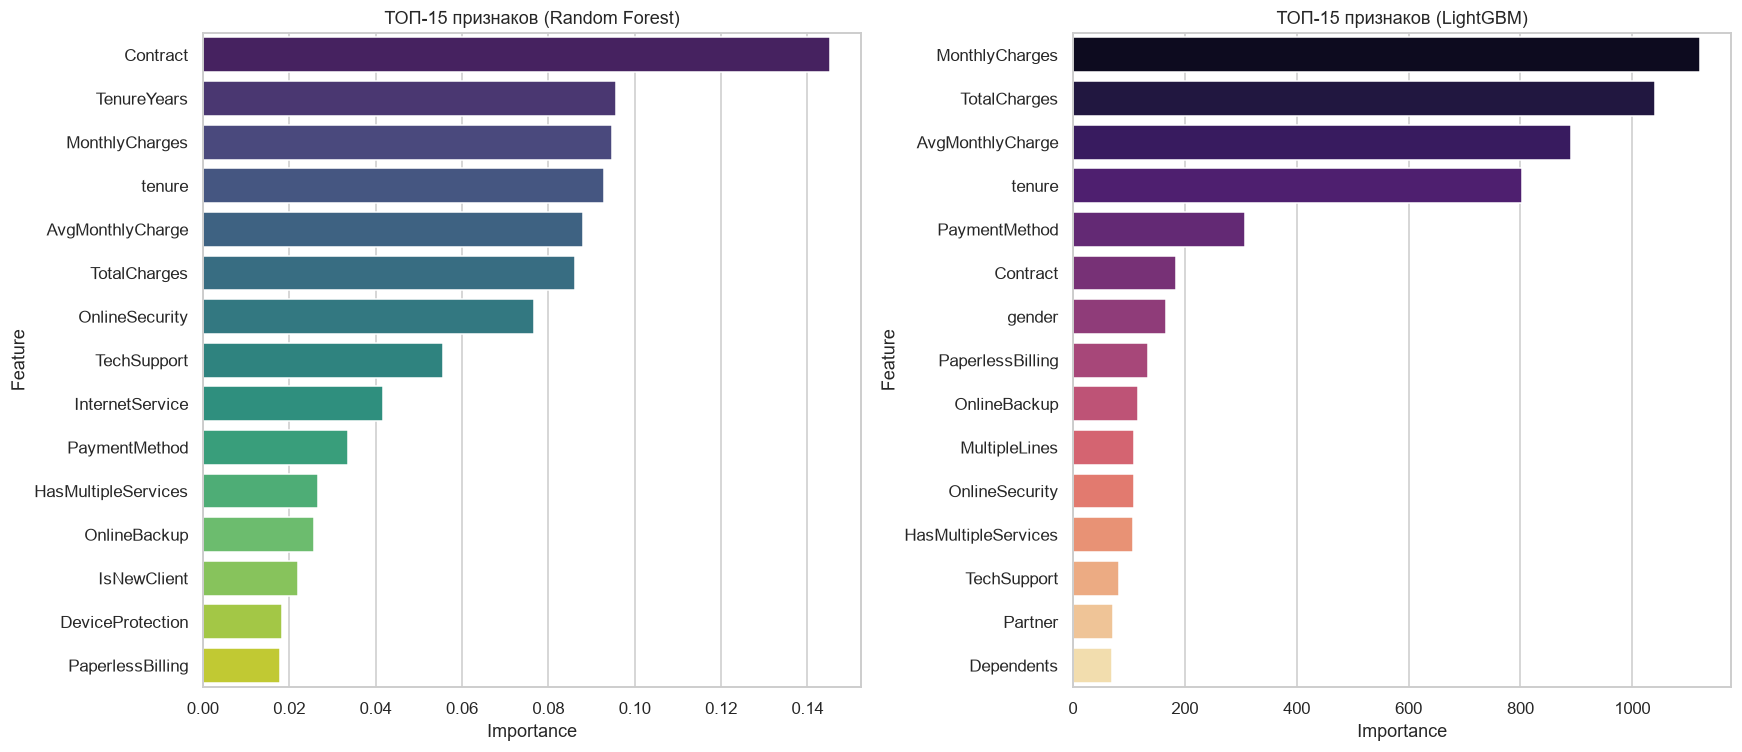

Топ-5 (RF):   ['Contract', 'TenureYears', 'MonthlyCharges', 'tenure', 'AvgMonthlyCharge']
Топ-5 (LGBM): ['MonthlyCharges', 'TotalCharges', 'AvgMonthlyCharge', 'tenure', 'PaymentMethod']


In [17]:
# Feature Importance для Random Forest и LightGBM
imp_rf = pd.DataFrame({'Feature': feature_cols, 'Importance': rf_model.feature_importances_}) \
           .sort_values('Importance', ascending=False)
imp_lgbm = pd.DataFrame({'Feature': feature_cols, 'Importance': lgbm_model.feature_importances_}) \
           .sort_values('Importance', ascending=False)

fig, axes = plt.subplots(1, 2, figsize=(16, 7))
for ax, imp, title, pal in [(axes[0], imp_rf, 'ТОП-15 признаков (Random Forest)', 'viridis'),
                            (axes[1], imp_lgbm, 'ТОП-15 признаков (LightGBM)', 'magma')]:
    sns.barplot(data=imp.head(15), x='Importance', y='Feature', hue='Feature',
                palette=pal, legend=False, ax=ax)
    ax.set_title(title)
plt.tight_layout()
plt.savefig('examples/feature_importance.png', dpi=130, bbox_inches='tight')
plt.show()

importances = imp_lgbm   # используется далее (SHAP dependence plot)
print('Топ-5 (RF):  ', imp_rf['Feature'].head(5).tolist())
print('Топ-5 (LGBM):', imp_lgbm['Feature'].head(5).tolist())

In [18]:
# Бизнес-срезы: как отток зависит от ключевых факторов (по исходным, некодированным данным)
def churn_rate(by):
    t = df.groupby(by)['Churn'].agg(['mean', 'count'])
    t['mean'] = (t['mean'] * 100).round(1)
    return t.rename(columns={'mean': 'Churn, %', 'count': 'Клиентов'})

print('— Тип контракта\n', churn_rate('Contract'), '\n')
print('— Тип интернета\n', churn_rate('InternetService'), '\n')
print('— Новый клиент (tenure ≤ 6 мес.)\n', churn_rate('IsNewClient'), '\n')
print('— Техподдержка\n', churn_rate('TechSupport'), '\n')
print('— Онлайн-безопасность\n', churn_rate('OnlineSecurity'), '\n')
print('— Способ оплаты\n', churn_rate('PaymentMethod'))

# Во сколько раз month-to-month уходят чаще клиентов с двухлетним контрактом
rates = df.groupby('Contract')['Churn'].mean()
print(f"\nMonth-to-month уходят в {rates['Month-to-month'] / rates['Two year']:.1f} раз чаще, "
      f"чем клиенты с двухлетним контрактом")

— Тип контракта
                 Churn, %  Клиентов
Contract                          
Month-to-month      42.7      3875
One year            11.3      1473
Two year             2.8      1695 

— Тип интернета
                  Churn, %  Клиентов
InternetService                    
DSL                  19.0      2421
Fiber optic          41.9      3096
No                    7.4      1526 

— Новый клиент (tenure ≤ 6 мес.)
              Churn, %  Клиентов
IsNewClient                    
0                19.5      5562
1                52.9      1481 

— Техподдержка
                      Churn, %  Клиентов
TechSupport                            
No                       41.6      3473
No internet service       7.4      1526
Yes                      15.2      2044 

— Онлайн-безопасность
                      Churn, %  Клиентов
OnlineSecurity                         
No                       41.8      3498
No internet service       7.4      1526
Yes                      14.6      2019 



**Feature Importance — что показали модели:**
- Random Forest, топ-5: `Contract`, `TenureYears`, `MonthlyCharges`, `tenure`, `AvgMonthlyCharge`.
- LightGBM (baseline), топ-5: `MonthlyCharges`, `TotalCharges`, `AvgMonthlyCharge`, `tenure`, `PaymentMethod`.

Списки заметно различаются: `Contract` — №1 у Random Forest, но не попал в топ-5 у LightGBM. Причина в том, что встроенная важность LightGBM (по умолчанию `importance_type='split'`) считает **число разбиений** по признаку, а непрерывные признаки (`MonthlyCharges`, `TotalCharges`) дробятся деревом много раз, тогда как трёхзначный `Contract` нужен всего в нескольких разбиениях, хотя вносит огромный вклад. Поэтому встроенной важности LightGBM доверять нельзя; более надёжная оценка — SHAP (раздел 10), где `Contract` с большим отрывом на первом месте.

**Бизнес-инсайты** (цифры — из таблиц срезов выше):
- **Тип контракта — главный рычаг.** Отток: month-to-month — **42.7 %**, годовой — 11.3 %, двухлетний — 2.8 %. Клиенты с помесячным контрактом уходят в **15.1 раза чаще**, чем с двухлетним. Рекомендация: скидки и бонусы за переход на длинный контракт.
- **Первые 6 месяцев — самый рискованный период:** у новых клиентов отток **52.9 %** против 19.5 % у остальных. Нужен онбординг и контроль качества сервиса в первые месяцы.
- **Fiber optic** — отток 41.9 % против 19.0 % у DSL и 7.4 % у клиентов без интернета. Стоит проверить качество услуги и цену относительно конкурентов.
- **Сервисные услуги удерживают:** без техподдержки уходят 41.6 % против 15.2 % с ней; без онлайн-безопасности — 41.8 % против 14.6 %. Можно предлагать эти услуги бесплатно на пробный период.
- **Electronic check — отток 45.3 %**, тогда как при автоплатеже (банковский перевод 16.7 %, карта 15.2 %) и чеке по почте (19.1 %) он в 2–3 раза ниже. Стимулировать переход на автоплатёж.

⚠️ Эти связи — **корреляции, а не причинность**: например, клиенты с Fiber optic часто одновременно новые и на помесячном контракте. Чтобы отделить эффекты, нужны контролируемые эксперименты (A/B-тесты удерживающих акций).

## Тюнинг гиперпараметров (Optuna)

In [19]:
# pip install optuna
import optuna
from sklearn.model_selection import cross_val_score, StratifiedKFold
optuna.logging.set_verbosity(optuna.logging.WARNING)

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

def objective(trial):
    # Пространство поиска гиперпараметров LightGBM
    params = {
        'n_estimators': trial.suggest_int('n_estimators', 100, 500, step=50),
        'num_leaves': trial.suggest_int('num_leaves', 10, 100, step=5),
        'max_depth': trial.suggest_int('max_depth', 3, 12),
        'learning_rate': trial.suggest_float('learning_rate', 0.01, 0.3, log=True),
        'subsample': trial.suggest_float('subsample', 0.5, 1.0),
        'colsample_bytree': trial.suggest_float('colsample_bytree', 0.5, 1.0),
        'min_child_samples': trial.suggest_int('min_child_samples', 5, 50),
        'reg_alpha': trial.suggest_float('reg_alpha', 1e-3, 10, log=True),
        'reg_lambda': trial.suggest_float('reg_lambda', 1e-3, 10, log=True),
    }
    # subsample_freq=1 нужен, иначе subsample в LightGBM игнорируется
    model = LGBMClassifier(**params, subsample_freq=1, class_weight='balanced',
                           random_state=RANDOM_STATE, verbose=-1, n_jobs=-1)
    # Кросс-валидация только на train (тест не трогаем!)
    return cross_val_score(model, X_train, y_train, cv=cv, scoring='roc_auc').mean()

# Запуск байесовской оптимизации (TPE, 30 испытаний)
study = optuna.create_study(direction='maximize',
                            sampler=optuna.samplers.TPESampler(seed=RANDOM_STATE))
study.optimize(objective, n_trials=30, show_progress_bar=True)

print(f'Best CV ROC-AUC: {study.best_value:.4f}')
for k, v in study.best_params.items():
    print(f'  {k}: {v}')

  0%|          | 0/30 [00:00<?, ?it/s]

Best CV ROC-AUC: 0.8496
  n_estimators: 350
  num_leaves: 90
  max_depth: 3
  learning_rate: 0.022943298923083385
  subsample: 0.6236369825139823
  colsample_bytree: 0.5164731483152039
  min_child_samples: 35
  reg_alpha: 0.002886956542416407
  reg_lambda: 7.328751913955659


ROC-AUC baseline (test): 0.8377
ROC-AUC Optuna   (test): 0.8503
Прирост: +0.0126 (+1.51%)
            Model  Accuracy  Precision  Recall     F1  ROC-AUC
LightGBM (Optuna)    0.7438     0.5111  0.7995 0.6236   0.8503


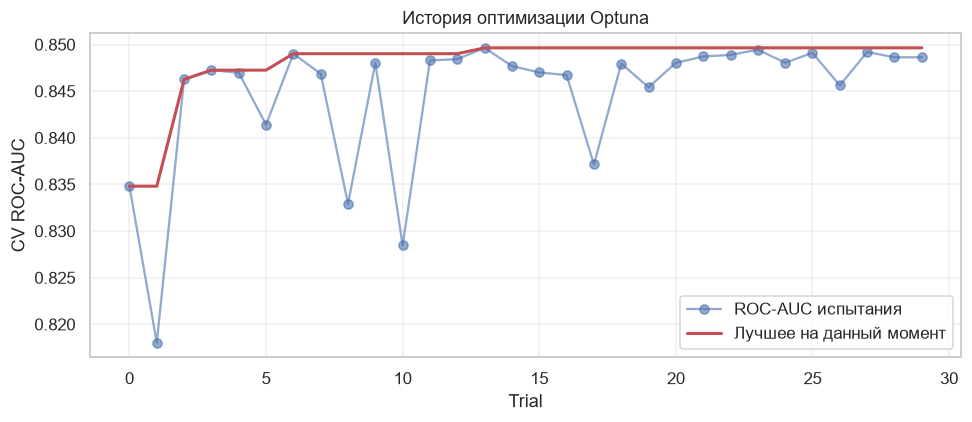

In [21]:
# Обучаем лучшую модель и сравниваем с baseline LightGBM на тесте
best_lgbm = LGBMClassifier(**study.best_params, subsample_freq=1, class_weight='balanced',
                           random_state=RANDOM_STATE, verbose=-1, n_jobs=-1)
best_lgbm.fit(X_train, y_train)

y_pred_best = best_lgbm.predict(X_test)
y_proba_best = best_lgbm.predict_proba(X_test)[:, 1]

base_auc = roc_auc_score(y_test, lgbm_model.predict_proba(X_test)[:, 1])
opt_auc = roc_auc_score(y_test, y_proba_best)
print(f'ROC-AUC baseline (test): {base_auc:.4f}')
print(f'ROC-AUC Optuna   (test): {opt_auc:.4f}')
print(f'Прирост: {opt_auc - base_auc:+.4f} ({(opt_auc / base_auc - 1) * 100:+.2f}%)')

opt_metrics = evaluate_model(best_lgbm, X_test, y_test, 'LightGBM (Optuna)')
print(pd.DataFrame([opt_metrics]).round(4).to_string(index=False))

# История оптимизации
plt.figure(figsize=(9, 4))
plt.plot([t.value for t in study.trials], 'o-', alpha=0.6, label='ROC-AUC испытания')
plt.plot(np.maximum.accumulate([t.value for t in study.trials]), 'r-', lw=2, label='Лучшее на данный момент')
plt.xlabel('Trial'); plt.ylabel('CV ROC-AUC'); plt.title('История оптимизации Optuna')
plt.legend(); plt.grid(alpha=0.3); plt.tight_layout(); plt.show()

### Бонус: Stacking
Дополнительно строим **стекинг** четырёх базовых моделей с логистической регрессией в роли мета-модели — проверяем, даёт ли комбинация разнородных ансамблей прирост.

In [22]:
from sklearn.ensemble import StackingClassifier
from sklearn.linear_model import LogisticRegression

# Мета-модель обучается на out-of-fold прогнозах (cv=5) базовых моделей
stack = StackingClassifier(
    estimators=[('rf', RandomForestClassifier(n_estimators=200, max_depth=10, class_weight='balanced',
                                              random_state=RANDOM_STATE, n_jobs=-1)),
                ('xgb', XGBClassifier(n_estimators=200, max_depth=6, learning_rate=0.1, subsample=0.9,
                                      colsample_bytree=0.9, scale_pos_weight=spw,
                                      random_state=RANDOM_STATE, eval_metric='logloss', n_jobs=-1)),
                ('lgbm', LGBMClassifier(**study.best_params, subsample_freq=1, class_weight='balanced',
                                        random_state=RANDOM_STATE, verbose=-1, n_jobs=-1)),
                ('cat', CatBoostClassifier(iterations=200, depth=6, learning_rate=0.1,
                                           auto_class_weights='Balanced', random_state=RANDOM_STATE, verbose=0))],
    final_estimator=LogisticRegression(max_iter=1000, class_weight='balanced'),
    cv=5, stack_method='predict_proba', n_jobs=1)

start = time.time()
stack.fit(X_train, y_train)
stack_time = time.time() - start
stack_metrics = evaluate_model(stack, X_test, y_test, 'Stacking (RF+XGB+LGBM+Cat)')
print(f'⏱️ Время обучения стекинга: {stack_time:.1f} сек')

# Итоговое сравнение всех подходов
final_df = pd.DataFrame(results + [opt_metrics, stack_metrics])
print(final_df.round(4).to_string(index=False))

⏱️ Время обучения стекинга: 10.3 сек
                     Model  Accuracy  Precision  Recall     F1  ROC-AUC
             Random Forest    0.7601     0.5346  0.7433 0.6219   0.8388
                   XGBoost    0.7708     0.5535  0.7059 0.6204   0.8300
                  LightGBM    0.7594     0.5332  0.7513 0.6238   0.8377
                  CatBoost    0.7488     0.5187  0.7433 0.6110   0.8409
         LightGBM (Optuna)    0.7438     0.5111  0.7995 0.6236   0.8503
Stacking (RF+XGB+LGBM+Cat)    0.7502     0.5190  0.8021 0.6303   0.8489


**Результаты тюнинга:**

| Показатель | Значение |
|---|---|
| Испытаний (TPE) | 30, 5-fold стратифицированная CV на train |
| Лучший CV ROC-AUC | 0.8496 |
| ROC-AUC на тесте: baseline LightGBM | 0.8377 |
| ROC-AUC на тесте: LightGBM + Optuna | **0.8503** |
| Прирост | **+0.0126 (+1.51 %)** |

- CV-оценка (0.8496) и тестовая (0.8503) практически совпадают — значит, подбор не переобучился на train, а тестовая выборка в нём не участвовала (утечки нет). Прирост +0.0094 есть и относительно лучшей базовой модели CatBoost (0.8409).
- **Что нашёл Optuna:** `n_estimators=350`, `learning_rate≈0.023`, **`max_depth=3`**, `min_child_samples=35`, `colsample_bytree≈0.52`, `subsample≈0.62`, `reg_lambda≈7.3`. То есть выбрана **более простая и сильно регуляризованная модель**: неглубокие деревья, малый шаг, подвыборки признаков и объектов, сильная L2-регуляризация. Это логично: данных мало, а сильных признаков немного. Параметр `num_leaves=90` при глубине 3 фактически не действует (дерево глубины 3 имеет максимум 8 листьев).
- **Цена прироста AUC на пороге 0.5:** Recall вырос с 0.7513 до **0.7995**, а Precision упал с 0.5332 до 0.5111 и Accuracy — с 0.7594 до 0.7438; F1 почти не изменился (0.6238 → 0.6236). Т. е. Optuna оптимизировал AUC (качество ранжирования), и выигрыш — в способности отделять уходящих от остающихся, а не в F1 при фиксированном пороге. Для практики порог лучше подбирать отдельно под бизнес-цель.
- **Бонус — Stacking** (RF + XGBoost + LightGBM-Optuna + CatBoost, мета-модель — логистическая регрессия): ROC-AUC **0.8489** (на 0.0014 ниже одиночной Optuna-модели — в пределах шума), Recall 0.8021, F1 **0.6303** (лучший среди всех), Accuracy 0.7502. Но обучение заняло **10.3 сек** (≈ 60 раз дольше baseline LightGBM) и даёт сложную систему из 4 моделей. Прирост F1 на +0.0067 не оправдывает сложность, поэтому **финальной выбрана LightGBM + Optuna** — самая простая из лучших по ROC-AUC.

## Интерпретация через SHAP

In [23]:
# pip install shap
import shap

# TreeExplainer — быстрый точный расчёт SHAP-значений для деревьев
explainer = shap.TreeExplainer(best_lgbm)
shap_values = explainer.shap_values(X_test)

# Унифицируем формат под разные версии shap: берём значения для класса «ушёл» (1)
if isinstance(shap_values, list):
    shap_values_class1 = shap_values[1]
elif np.ndim(shap_values) == 3:
    shap_values_class1 = shap_values[:, :, 1]
else:
    shap_values_class1 = shap_values

ev = explainer.expected_value
base_value = float(np.ravel(ev)[1] if np.size(ev) > 1 else np.ravel(ev)[0])
print('SHAP-значения:', shap_values_class1.shape, '| base value (log-odds):', round(base_value, 4))

SHAP-значения: (1409, 23) | base value (log-odds): -0.635


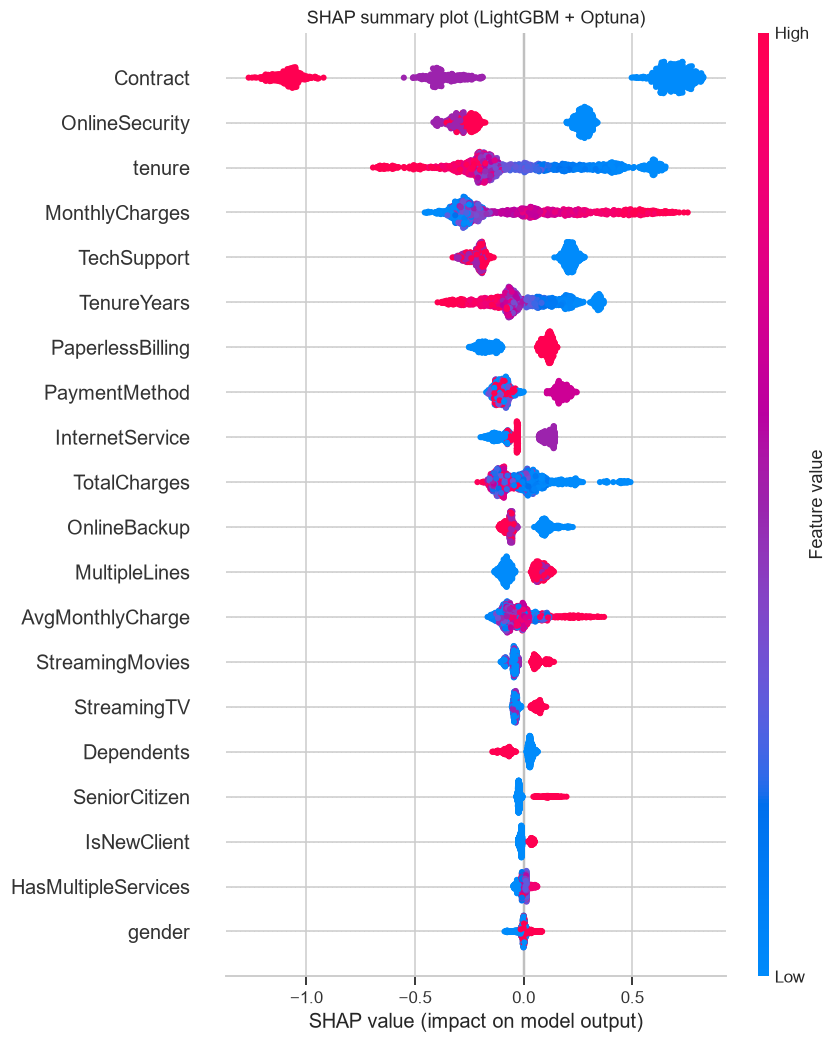

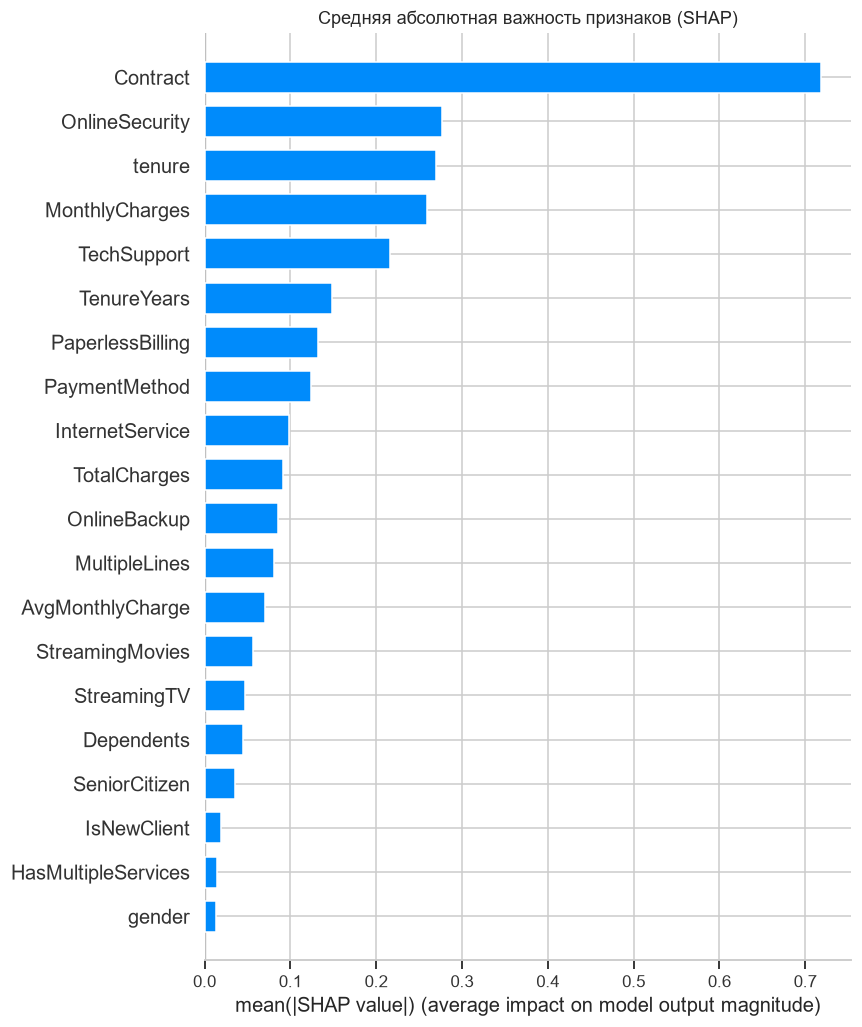

Топ-8 по SHAP:
 Contract            0.7179
OnlineSecurity      0.2770
tenure              0.2695
MonthlyCharges      0.2594
TechSupport         0.2159
TenureYears         0.1481
PaperlessBilling    0.1317
PaymentMethod       0.1238
dtype: float64


In [24]:
# Summary plot (beeswarm) — глобальная важность и направление влияния
shap.summary_plot(shap_values_class1, X_test, plot_type='dot', show=False)
plt.title('SHAP summary plot (LightGBM + Optuna)')
plt.savefig('examples/shap_summary.png', dpi=130, bbox_inches='tight')
plt.show()

# Bar plot — средний |SHAP| по признакам
shap.summary_plot(shap_values_class1, X_test, plot_type='bar', show=False)
plt.title('Средняя абсолютная важность признаков (SHAP)')
plt.tight_layout(); plt.show()

shap_importance = pd.Series(np.abs(shap_values_class1).mean(axis=0), index=X_test.columns) \
                    .sort_values(ascending=False)
print('Топ-8 по SHAP:\n', shap_importance.head(8).round(4))

Клиент (позиция в test) #1090, вероятность ухода = 0.9509
{'Contract': 0.0, 'tenure': 1.0, 'InternetService': 1.0, 'MonthlyCharges': 95.1}


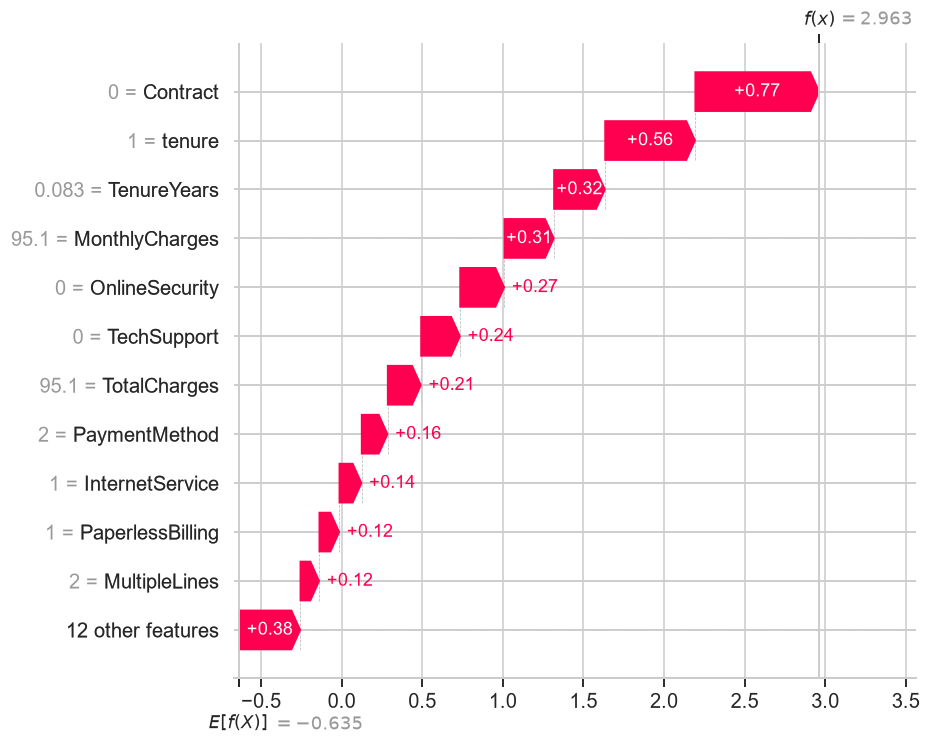


Самые сильные факторы риска для этого клиента (SHAP, log-odds):
Contract          0.770
tenure            0.559
TenureYears       0.317
MonthlyCharges    0.308
OnlineSecurity    0.275
dtype: float64


In [25]:
# Waterfall plot — объяснение прогноза для клиента с максимальным риском ухода
worst_idx = int(np.argmax(y_proba_best))
print(f'Клиент (позиция в test) #{worst_idx}, вероятность ухода = {y_proba_best[worst_idx]:.4f}')
print(X_test.iloc[worst_idx][['Contract', 'tenure', 'InternetService', 'MonthlyCharges']].to_dict())

explanation = shap.Explanation(values=shap_values_class1[worst_idx], base_values=base_value,
                               data=X_test.iloc[worst_idx].values, feature_names=X_test.columns.tolist())
shap.plots.waterfall(explanation, max_display=12, show=False)
plt.savefig('examples/shap_waterfall.png', dpi=130, bbox_inches='tight')
plt.show()

# Топ-5 вкладов для этого клиента в текстовом виде
contrib = pd.Series(shap_values_class1[worst_idx], index=X_test.columns)
print('\nСамые сильные факторы риска для этого клиента (SHAP, log-odds):')
print(contrib.sort_values(ascending=False).head(5).round(3))

Главный признак по SHAP: Contract


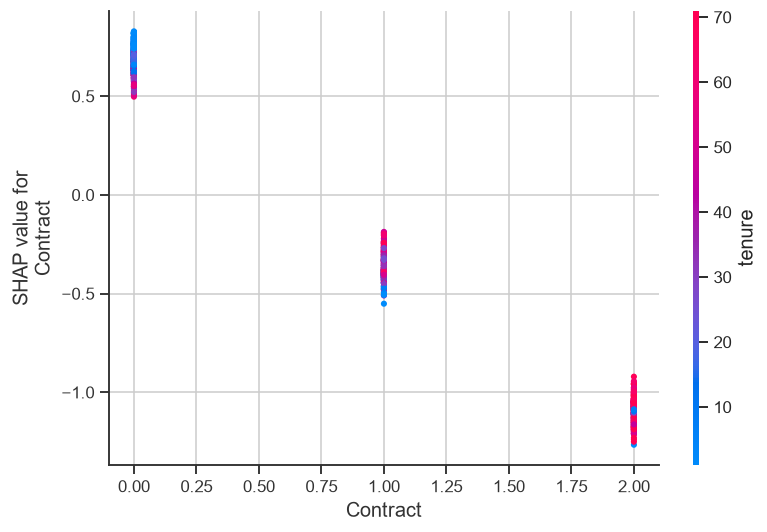

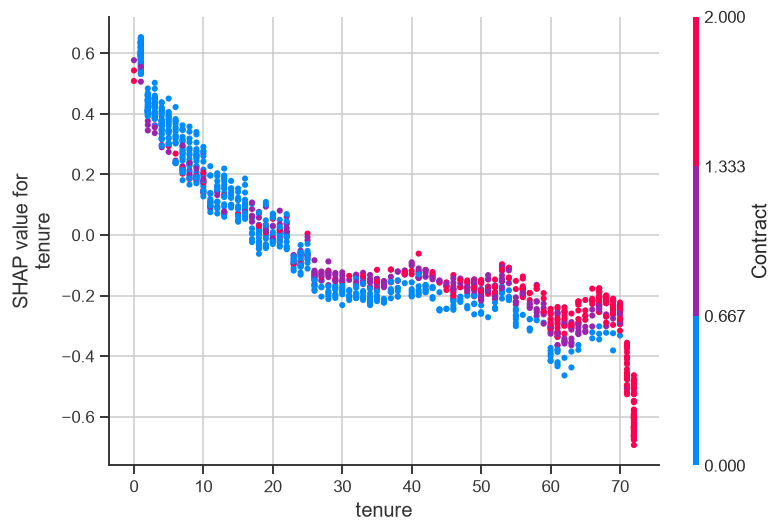

In [26]:
# Dependence plot — зависимость вклада от значения главного признака
top_feature = shap_importance.index[0]
print('Главный признак по SHAP:', top_feature)
shap.dependence_plot(top_feature, shap_values_class1, X_test, show=False)
plt.tight_layout(); plt.show()

# Дополнительно: dependence для tenure (если это не главный признак)
if top_feature != 'tenure':
    shap.dependence_plot('tenure', shap_values_class1, X_test, show=False)
    plt.tight_layout(); plt.show()

**Что показывает SHAP** (для LightGBM + Optuna, 1409 клиентов теста; значения в log-odds, базовое значение −0.635):

**Глобальная важность (средний |SHAP|):**

| Признак | Средний \|SHAP\| |
|---|---|
| Contract | 0.718 |
| OnlineSecurity | 0.277 |
| tenure | 0.270 |
| MonthlyCharges | 0.259 |
| TechSupport | 0.216 |
| TenureYears | 0.148 |
| PaperlessBilling | 0.132 |
| PaymentMethod | 0.124 |

- **`Contract` — абсолютный лидер**, его вклад в 2.6 раза больше следующего признака (`OnlineSecurity`). Это согласуется с таблицей срезов (отток 42.7 % / 11.3 % / 2.8 %) и с Random Forest, но **расходится со встроенной важностью LightGBM** (раздел 8), где `Contract` не вошёл в топ-5 — подтверждение того, что split-важность вводит в заблуждение.
- Далее идут `OnlineSecurity`, `tenure`, `MonthlyCharges`, `TechSupport`: отсутствие онлайн-безопасности и техподдержки, малый стаж и высокие платежи повышают риск (направления эффектов подтверждаются срезами из раздела 8 и видны на beeswarm-графике цветом точек).
- **`tenure` и `TenureYears` — одна и та же информация**, поэтому SHAP делит её между двумя признаками (0.270 + 0.148 = 0.418). Суммарно стаж — важнее, чем показывает каждая строка по отдельности, и по силе сравним с `OnlineSecurity`.
- **Waterfall plot** — клиент #1090 с максимальным риском (вероятность ухода **0.9509**): помесячный контракт (`Contract = 0`), стаж 1 месяц, Fiber optic, `MonthlyCharges = 95.1`. Главные факторы риска: `Contract` (+0.770), `tenure` (+0.559), `TenureYears` (+0.317), `MonthlyCharges` (+0.308), `OnlineSecurity` (+0.275). Если сложить `tenure` и `TenureYears`, стаж в 1 месяц даёт +0.876 — это второй по силе фактор после контракта. Отсутствие онлайн-безопасности добавляет ещё +0.275.
- **Базовое значение −0.635** log-odds соответствует вероятности ≈ 0.35, а не 0.265 — это следствие `class_weight='balanced'`: веса классов сдвигают вероятности вверх, поэтому предсказанные вероятности нельзя читать как «настоящие» (нужна калибровка).
- **Dependence plot** главного признака `Contract` показывает, что вклад определяется практически только категорией контракта (0 — month-to-month → положительный SHAP, 1 и 2 — отрицательный); цветом показано взаимодействие со вторым признаком.
- Практическая польза: SHAP объясняет **почему** конкретный клиент в группе риска, что позволяет персонализировать удерживающие предложения (например, клиенту выше — предложить годовой контракт со скидкой и бесплатный пакет безопасности).

## Сохранение модели

In [27]:
import joblib

# Сохраняем все модели, scaler, кодировщики и список признаков
joblib.dump(rf_model,   'models/rf_model.pkl')
joblib.dump(xgb_model,  'models/xgb_model.pkl')
joblib.dump(lgbm_model, 'models/lgbm_model.pkl')
joblib.dump(cat_model,  'models/cat_model.pkl')
joblib.dump(best_lgbm,  'models/best_model.pkl')            # лучшая: LightGBM + Optuna
joblib.dump(scaler,     'models/scaler.pkl')
joblib.dump(label_encoders, 'models/label_encoders.pkl')    # словарь {признак: LabelEncoder}

with open('models/feature_cols.json', 'w', encoding='utf-8') as f:
    json.dump(feature_cols, f, ensure_ascii=False, indent=2)

# Метрики всех моделей + параметры лучшей
def as_dict(r):
    return {k: float(v) for k, v in r.items() if k != 'Model'}

metrics = {
    'random_forest': as_dict(results[0]),
    'xgboost': as_dict(results[1]),
    'lightgbm': as_dict(results[2]),
    'catboost': as_dict(results[3]),
    'lightgbm_optuna': as_dict(opt_metrics),
    'stacking_bonus': as_dict(stack_metrics),
    'train_time_sec': {k: float(v) for k, v in train_times.items()},
    'best_model': 'LightGBM (Optuna)',
    'best_cv_roc_auc': float(study.best_value),
    'best_test_roc_auc': float(opt_auc),
    'best_params': study.best_params,
    'n_trials': len(study.trials),
}
with open('models/metrics.json', 'w', encoding='utf-8') as f:
    json.dump(metrics, f, indent=2, ensure_ascii=False)

print('✅ Сохранено:', sorted(os.listdir('models')))

✅ Сохранено: ['best_model.pkl', 'cat_model.pkl', 'feature_cols.json', 'label_encoders.pkl', 'lgbm_model.pkl', 'metrics.json', 'rf_model.pkl', 'scaler.pkl', 'xgb_model.pkl']


In [28]:
# requirements.txt и README модуля (генерируются автоматически из фактических версий)
import sklearn, xgboost, lightgbm, catboost, matplotlib
req = f'''pandas=={pd.__version__}
numpy=={np.__version__}
scikit-learn=={sklearn.__version__}
xgboost=={xgboost.__version__}
lightgbm=={lightgbm.__version__}
catboost=={catboost.__version__}
optuna=={optuna.__version__}
shap=={shap.__version__}
matplotlib=={matplotlib.__version__}
seaborn=={sns.__version__}
joblib=={joblib.__version__}
requests
'''
with open('requirements.txt', 'w') as f:
    f.write(req)

table = final_df.round(3).copy()
md_table = '| Модель | Accuracy | Precision | Recall | F1 | ROC-AUC |\n|---|---|---|---|---|---|\n' + '\n'.join(
    f'| {r["Model"]} | {r["Accuracy"]} | {r["Precision"]} | {r["Recall"]} | {r["F1"]} | {r["ROC-AUC"]} |' for _, r in table.iterrows())

readme = f'''# 📉 Module 3 — Customer Churn: Ансамблевые методы

## 📊 Результаты (тестовая выборка)

{md_table}

## 🚀 Быстрый старт

```python
import joblib, requests
from io import BytesIO
BASE_URL = "https://raw.githubusercontent.com/<username>/ml-course-<фамилия>/main/module-3-churn"
model = joblib.load(BytesIO(requests.get(f"{{BASE_URL}}/models/best_model.pkl").content))
```

## 📁 Структура
- `notebook.ipynb` — полный отчёт
- `models/` — модели, scaler, кодировщики, метрики
- `data/` — датасет и описание
- `examples/` — графики EDA, SHAP, Feature Importance, ROC
'''
with open('README.md', 'w', encoding='utf-8') as f:
    f.write(readme)
print('✅ requirements.txt и README.md созданы')

✅ requirements.txt и README.md созданы


**Что сохранено в `models/`:** `rf_model.pkl`, `xgb_model.pkl`, `lgbm_model.pkl`, `cat_model.pkl`, `best_model.pkl` (LightGBM + Optuna), `scaler.pkl`, `label_encoders.pkl`, `feature_cols.json` (23 признака) и `metrics.json` (метрики всех моделей, время обучения, лучшие параметры Optuna). Также сгенерирован `requirements.txt` с реальными версиями библиотек.

Загрузка в репозиторий:
```bash
git add module-3-churn/
git commit -m "Module 3: Add trained ensemble models and notebook"
git push origin main
```

## Загрузка модели из репозитория

In [29]:
import requests
from io import BytesIO

GITHUB_USER, REPO = 'fivifri', 'ml-course-emelyanova'
BASE_URL = f'https://raw.githubusercontent.com/{GITHUB_USER}/{REPO}/main/module-3-churn'

def load_from_repo(rel_path, as_json=False, timeout=30):
    # Скачиваем файл по raw-ссылке; при неудаче читаем локальную копию
    url = f'{BASE_URL}/{rel_path}'
    try:
        r = requests.get(url, timeout=timeout)
        r.raise_for_status()
        print(f'🌐 Загружено из репозитория: {url}')
        return r.json() if as_json else joblib.load(BytesIO(r.content))
    except Exception as e:
        print(f'⚠️ Не удалось скачать ({type(e).__name__}); читаю локальный файл {rel_path}')
        if as_json:
            with open(rel_path, encoding='utf-8') as f:
                return json.load(f)
        return joblib.load(rel_path)

best_lgbm_loaded = load_from_repo('models/best_model.pkl')
feature_cols_loaded = load_from_repo('models/feature_cols.json', as_json=True)
print(f'✅ Модель загружена: {type(best_lgbm_loaded).__name__}')
print(f'✅ Загружено {len(feature_cols_loaded)} признаков')

🌐 Загружено из репозитория: https://raw.githubusercontent.com/fivifri/ml-course-emelyanova/main/module-3-churn/models/best_model.pkl
🌐 Загружено из репозитория: https://raw.githubusercontent.com/fivifri/ml-course-emelyanova/main/module-3-churn/models/feature_cols.json
✅ Модель загружена: LGBMClassifier
✅ Загружено 23 признаков


In [30]:
# Проверка: предсказания загруженной и исходной модели на 3 клиентах должны совпасть
sample = X_test[feature_cols_loaded].iloc[:3]
y_pred_loaded = best_lgbm_loaded.predict(sample)
y_pred_original = best_lgbm.predict(sample)
proba_loaded = best_lgbm_loaded.predict_proba(sample)[:, 1]

print(f'Загруженная модель:  {y_pred_loaded}')
print(f'Исходная модель:     {y_pred_original}')
print(f'Вероятности ухода:   {proba_loaded.round(3)}')
print(f'Совпадают: {np.array_equal(y_pred_loaded, y_pred_original)}')

Загруженная модель:  [0 1 0]
Исходная модель:     [0 1 0]
Вероятности ухода:   [0.086 0.901 0.197]
Совпадают: True


Модель успешно загружена по raw-ссылке GitHub (`https://raw.githubusercontent.com/fivifri/ml-course-emelyanova/main/module-3-churn/models/best_model.pkl`): в выводе обе загрузки отмечены 🌐, т. е. использовалась именно версия из репозитория, а не локальная копия. Загружен объект `LGBMClassifier` и список из 23 признаков.

**Проверка работоспособности:** на первых трёх клиентах теста загруженная и исходная модели дали одинаковые предсказания `[0 1 0]`, вероятности ухода — `0.086`, `0.901`, `0.197`, проверка `Совпадают: True`. Первый и третий клиенты — «останутся» с низким риском, второй — «уйдёт» с вероятностью 90 %. Модель из репозитория полностью воспроизводит исходную.

## Выводы

In [31]:
# Итоговая сводка для выводов (числа подставляются автоматически)
best_row = final_df.sort_values('ROC-AUC', ascending=False).iloc[0]
print(f'Лучший ROC-AUC на тесте: {best_row["Model"]} = {best_row["ROC-AUC"]:.4f}')
print(f'LightGBM baseline → Optuna: {base_auc:.4f} → {opt_auc:.4f} ({opt_auc - base_auc:+.4f})')
print(f'Финальная модель (Optuna): Recall={opt_metrics["Recall"]:.3f}, '
      f'Precision={opt_metrics["Precision"]:.3f}, F1={opt_metrics["F1"]:.3f}')
print('Топ-3 признака по SHAP:', shap_importance.index[:3].tolist())

Лучший ROC-AUC на тесте: LightGBM (Optuna) = 0.8503
LightGBM baseline → Optuna: 0.8377 → 0.8503 (+0.0126)
Финальная модель (Optuna): Recall=0.799, Precision=0.511, F1=0.624
Топ-3 признака по SHAP: ['Contract', 'OnlineSecurity', 'tenure']


### ✅ Что получилось
- Построены и сравнены 4 ансамблевые модели. На тесте их ROC-AUC лежит в узком диапазоне **0.830–0.841** (CatBoost 0.8409, Random Forest 0.8388, LightGBM 0.8377, XGBoost 0.8300): различия сопоставимы с шумом, все четыре модели качественно эквивалентны.
- **Финальная модель — LightGBM + Optuna: ROC-AUC = 0.8503** (+0.0126 к baseline LightGBM, +0.0094 к лучшей базовой модели), Recall = 0.7995, Precision = 0.5111, F1 = 0.6236, Accuracy = 0.7438. CV-оценка 0.8496 совпала с тестовой, значит, переобучения при подборе нет.
- Бонус: Stacking дал ROC-AUC 0.8489 и лучший F1 (0.6303), но обучается в ≈ 60 раз дольше и не превосходит одиночную Optuna-модель по AUC.
- Модель сохранена, воспроизводимо загружается из GitHub и даёт те же предсказания (`[0 1 0]`, совпадение `True`).
- Ключевые инсайты (SHAP + срезы): главный фактор оттока — **тип контракта** (month-to-month 42.7 % против 2.8 % у двухлетнего, т. е. в 15 раз чаще); далее — отсутствие онлайн-безопасности и техподдержки, малый стаж (новые клиенты — 52.9 % оттока), высокие ежемесячные платежи, Fiber optic (41.9 %) и оплата электронным чеком (45.3 %).

### ⚠️ Какие были трудности
- **Дисбаланс классов (26.5 % ушедших):** Accuracy неинформативна. Веса классов подняли Recall до 0.71–0.80, но Precision осталась на уровне 0.51–0.55: из клиентов, помеченных как «уйдут», реально уходит лишь около половины.
- **Пропуски в `TotalCharges`:** значения хранились как строки с пробелами у клиентов с `tenure = 0` (11 строк); решено преобразованием `errors='coerce'` и заполнением медианой.
- **Ненадёжная встроенная важность:** по `feature_importances_` LightGBM `Contract` не вошёл в топ-5, а по SHAP он лидирует с большим отрывом — пришлось опираться на SHAP.
- **Дублирование признаков:** `TenureYears` — копия `tenure`, из-за чего SHAP делит их важность между двумя строками.
- **Малый прирост и шум оценки:** разброс AUC между базовыми моделями (0.011) сопоставим с погрешностью одной hold-out-выборки (374 положительных объекта), поэтому «лучшую» базовую модель выбрать статистически нельзя.
- **Смещённые вероятности:** из-за `class_weight='balanced'` базовая вероятность по SHAP ≈ 0.35 вместо 0.265, предсказанные вероятности нельзя интерпретировать буквально.

### 🚀 Идеи улучшения
1. **Подбор порога классификации** по бизнес-функции (стоимость удерживающей акции против стоимости потери клиента) вместо 0.5 — сейчас при пороге 0.5 Precision всего 0.51.
2. **Калибровка вероятностей** (`CalibratedClassifierCV`, Platt/Isotonic), чтобы вероятности можно было использовать для расчёта ожидаемых потерь.
3. **Удалить дублирующие признаки** (`TenureYears`) и проверить, не ухудшится ли качество; добавить взаимодействия (контракт × интернет, tenure × цена).
4. **SMOTE / undersampling** — сравнить с весами классов по ROC-AUC и PR-AUC.
5. **Нативные категориальные признаки CatBoost** (`cat_features`) вместо `LabelEncoder`.
6. **Повторная кросс-валидация и доверительные интервалы метрик** вместо одного hold-out — чтобы честно сравнивать модели с разницей 0.003–0.01.
7. **Больше испытаний Optuna** (100+) с pruning и ограничением пространства (при `max_depth=3` параметр `num_leaves` не нужен).
8. **Feature Store и MLflow** для версионирования признаков и экспериментов; мониторинг дрейфа данных в продакшене.
9. **Uplift-моделирование:** предсказывать не вероятность ухода, а эффект от удерживающей акции — так бюджет тратится на клиентов, которых реально можно удержать.

## Источники

1. Breiman, L. (2001). Random Forests. *Machine Learning*, 45(1), 5–32.
2. Chen, T., & Guestrin, C. (2016). XGBoost: A Scalable Tree Boosting System. *KDD '16*.
3. Ke, G. et al. (2017). LightGBM: A Highly Efficient Gradient Boosting Decision Tree. *NeurIPS 2017*.
4. Prokhorenkova, L. et al. (2018). CatBoost: unbiased boosting with categorical features. *NeurIPS 2018*.
5. Lundberg, S., & Lee, S.-I. (2017). A Unified Approach to Interpreting Model Predictions. *NeurIPS 2017*.
6. Akiba, T. et al. (2019). Optuna: A Next-generation Hyperparameter Optimization Framework. *KDD '19*.
7. Friedman, J. (2001). Greedy Function Approximation: A Gradient Boosting Machine. *Annals of Statistics*, 29(5).
8. Telco Customer Churn (Kaggle, BlastChar): https://www.kaggle.com/datasets/blastchar/telco-customer-churn
9. Документация scikit-learn: https://scikit-learn.org/stable/modules/ensemble.html

## Приложение

Полный код с комментариями — это ячейки данного ноутбука (разделы 4–12). Файл `requirements.txt` генерируется автоматически в разделе 11 с реальными версиями библиотек. Ориентировочный состав окружения:

```
pandas
numpy
scikit-learn
xgboost
lightgbm
catboost
optuna
shap
matplotlib
seaborn
joblib
requests
```